<a href="https://colab.research.google.com/github/miriamamin1213-ux/ValidationSET/blob/main/HancockGPT2Gen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Device: cuda


Downloading...
From: https://drive.google.com/uc?id=1F_kngwHn6KkOQqSwtYXCaF-bT8DZt__Q
To: /content/clinical_data.json
100%|██████████| 810k/810k [00:00<00:00, 18.0MB/s]
Downloading...
From: https://drive.google.com/uc?id=1KY3NS9q3lfodf-t3g92S1JE3Vqcl6o3F
To: /content/pathological_data.json
100%|██████████| 458k/458k [00:00<00:00, 22.9MB/s]


Patients: 332
HPV classes:
 HPV_Label
0    191
1    141
Name: count, dtype: int64
Required six features: ['age_at_initial_diagnosis', 'sex', 'smoking_status', 'primary_tumor_site', 'primarily_metastasis', 'pN_stage']
N-stage source column: pN_stage
Train: 215 classes: [123  92]
Validation: 50 classes: [29 21]
Test: 67 classes: [39 28]
Example prompt:
 Q: Predict this patient's Human Papillomavirus (HPV) status using the clinical information available. Age at initial diagnosis: 53. Sex: male. Smoking status: smoker. Primary tumour site: Oropharynx. Primarily metastasis: no. Pathological N stage: pN0. Is this patient HPV positive? Answer with only Yes or No.
A: 
Target: No


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Class weights: [0.87398374 1.1684783 ]
Epoch 50/500 | Train Loss=0.2677 | Val Loss=0.2873 | Val ROC-AUC=0.7997 | Val PR-AUC=0.7625 | Val BA=0.7537 | Threshold=0.468708
Epoch 100/500 | Train Loss=0.1610 | Val Loss=0.7113 | Val ROC-AUC=0.6002 | Val PR-AUC=0.4983 | Val BA=0.6330 | Threshold=0.572359
Epoch 150/500 | Train Loss=0.0997 | Val Loss=0.8455 | Val ROC-AUC=0.6059 | Val PR-AUC=0.5372 | Val BA=0.6248 | Threshold=0.011185
Epoch 200/500 | Train Loss=0.0545 | Val Loss=1.7184 | Val ROC-AUC=0.5985 | Val PR-AUC=0.4911 | Val BA=0.6141 | Threshold=0.000005
Epoch 250/500 | Train Loss=0.0258 | Val Loss=1.9541 | Val ROC-AUC=0.5714 | Val PR-AUC=0.4805 | Val BA=0.6034 | Threshold=0.000001
Epoch 300/500 | Train Loss=0.0328 | Val Loss=2.0160 | Val ROC-AUC=0.5805 | Val PR-AUC=0.5886 | Val BA=0.6133 | Threshold=0.036088
Epoch 350/500 | Train Loss=0.0396 | Val Loss=1.5774 | Val ROC-AUC=0.5640 | Val PR-AUC=0.5210 | Val BA=0.5837 | Threshold=0.000142
Epoch 400/500 | Train Loss=0.0342 | Val Loss=2.0922 

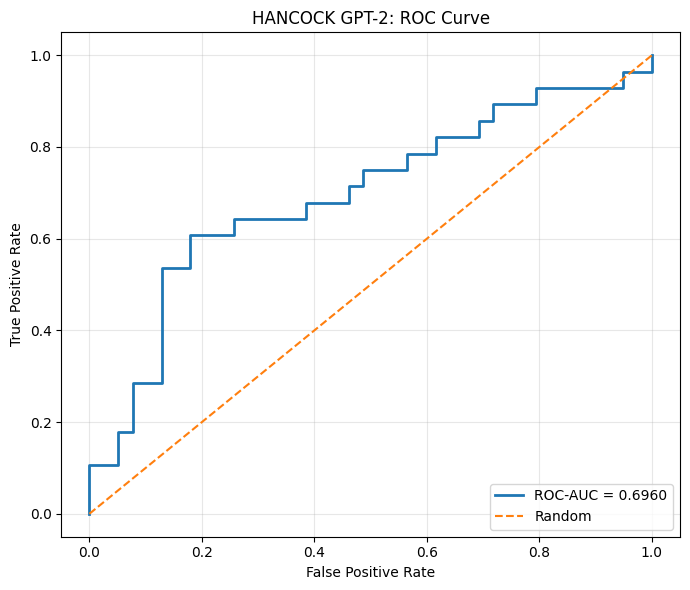

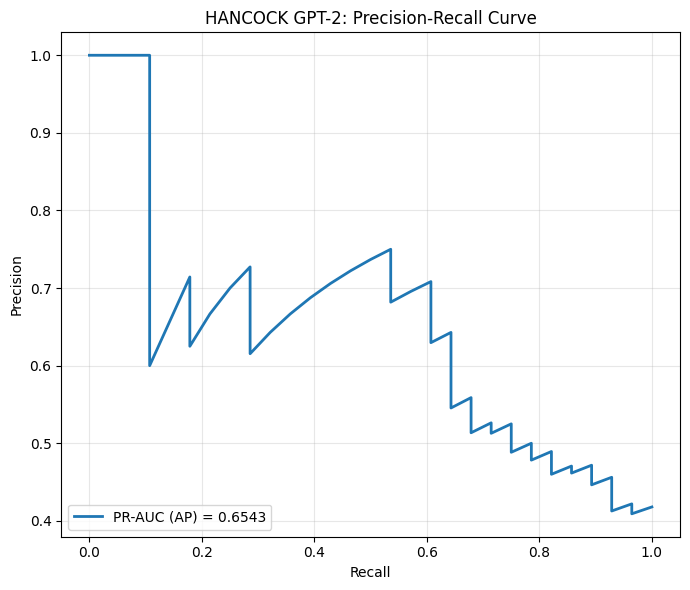


Features used: ['age_at_initial_diagnosis', 'sex', 'smoking_status', 'primary_tumor_site', 'primarily_metastasis', 'pN_stage']
All HANCOCK results saved to: /content/ROC_HANCOCK_GPT2
AUC comparison saved to: /content/model_roc_pr_auc_comparison.csv
Dataset Model       Checkpoint_Selected_By  Best_Epoch  Test_ROC_AUC  Test_PR_AUC
HANCOCK GPT-2              Validation_Loss          37      0.711538     0.630873
HANCOCK GPT-2           Validation_ROC_AUC          50      0.695971     0.654251
HANCOCK GPT-2            Validation_PR_AUC          49      0.717949     0.685695
HANCOCK GPT-2 Validation_Balanced_Accuracy          28      0.700549     0.612819


In [1]:

# ============================================================
# 1. IMPORT LIBRARIES, SET RANDOM SEED AND SELECT DEVICE
# ============================================================
import os, random, json, gdown
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from transformers import GPT2Tokenizer, GPT2LMHeadModel
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, balanced_accuracy_score, roc_auc_score,
    average_precision_score, confusion_matrix, roc_curve,
    precision_recall_curve
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


# ============================================================
# 2. LOAD AND MERGE HANCOCK CLINICAL/PATHOLOGICAL DATA
# ============================================================
CLINICAL_FILE = "clinical_data.json"
PATHOLOGICAL_FILE = "pathological_data.json"

if not os.path.exists(CLINICAL_FILE):
    if gdown.download(
        id="1F_kngwHn6KkOQqSwtYXCaF-bT8DZt__Q",
        output=CLINICAL_FILE, quiet=False
    ) is None:
        raise FileNotFoundError("Could not download clinical_data.json.")

if not os.path.exists(PATHOLOGICAL_FILE):
    if gdown.download(
        id="1KY3NS9q3lfodf-t3g92S1JE3Vqcl6o3F",
        output=PATHOLOGICAL_FILE, quiet=False
    ) is None:
        raise FileNotFoundError("Could not download pathological_data.json.")


def load_json_table(path):
    with open(path, "r", encoding="utf-8") as f:
        obj = json.load(f)

    if isinstance(obj, list):
        return pd.DataFrame(obj)

    if isinstance(obj, dict):
        for key in ["data", "records", "patients", "items"]:
            if key in obj and isinstance(obj[key], list):
                return pd.DataFrame(obj[key])
        try:
            return pd.DataFrame(obj)
        except ValueError:
            pass

    raise ValueError(f"Could not convert {path} to a table.")


clinical_df = load_json_table(CLINICAL_FILE)
pathological_df = load_json_table(PATHOLOGICAL_FILE)

if "patient_id" not in clinical_df.columns or \
   "patient_id" not in pathological_df.columns:
    raise KeyError("Both JSON files must contain 'patient_id'.")

df = clinical_df.merge(
    pathological_df, on="patient_id", how="left",
    suffixes=("", "_path")
)


def resolve_col(candidates, required=False):
    for c in candidates:
        if c in df.columns:
            return c
    if required:
        raise KeyError(
            f"Required column not found: {candidates}. "
            f"Available columns: {df.columns.tolist()}"
        )
    return None


# ============================================================
# 3. SELECT EXACTLY SIX REQUIRED FEATURES AND DEFINE HPV TARGET
# ============================================================
target_col = resolve_col(
    ["hpv_association_p16", "hpv_association_p16_path"],
    required=True
)

# Five original HANCOCK features plus required pathological N stage.
feature_candidates = {
    "age_at_initial_diagnosis": [
        "age_at_initial_diagnosis", "age_at_initial_diagnosis_path"
    ],
    "sex": ["sex", "sex_path"],
    "smoking_status": ["smoking_status", "smoking_status_path"],
    "primary_tumor_site": ["primary_tumor_site", "primary_tumor_site_path"],
    "primarily_metastasis": ["primarily_metastasis", "primarily_metastasis_path"],
    "pN_stage": [
        "pN_stage", "pN_stage_path",
        "pathological_N_stage", "pathological_n_stage"
    ]
}

# All six features are required. Missing any feature stops execution.
feature_map = {
    name: resolve_col(candidates, required=True)
    for name, candidates in feature_candidates.items()
}
features = list(feature_candidates.keys())

df = df.dropna(subset=[target_col]).copy()


def normalize_target(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()

    if s in ["negative", "neg", "0", "false", "no"]:
        return 0
    if s in ["positive", "pos", "1", "true", "yes"]:
        return 1

    try:
        n = float(s)
        if n in [0, 1]:
            return int(n)
    except ValueError:
        pass

    return np.nan


df["HPV_Label"] = df[target_col].apply(normalize_target)
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)

feature_df = df[[feature_map[c] for c in features]].copy()
feature_df = feature_df.rename(
    columns={feature_map[c]: c for c in features}
)
df = pd.concat([feature_df, df[["HPV_Label"]]], axis=1)
df = df.loc[:, ~df.columns.duplicated()].copy()

# Convert age to numeric; keep N stage categorical if encoded as text.
df["age_at_initial_diagnosis"] = pd.to_numeric(
    df["age_at_initial_diagnosis"], errors="coerce"
)

print("Patients:", len(df))
print("HPV classes:\n", df["HPV_Label"].value_counts().sort_index())
print("Required six features:", features)
print("N-stage source column:", feature_map["pN_stage"])


# ============================================================
# 4. STRATIFIED TRAIN/VALIDATION/TEST SPLIT (65/15/20)
# ============================================================
train_val_df, test_df = train_test_split(
    df, test_size=0.20, random_state=SEED,
    stratify=df["HPV_Label"]
)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.1875, random_state=SEED,
    stratify=train_val_df["HPV_Label"]
)

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()


# ============================================================
# 5. HANDLE MISSING VALUES USING TRAINING DATA ONLY
# ============================================================
fill_values = {}

for c in features:
    if pd.api.types.is_numeric_dtype(train_df[c]):
        value = train_df[c].median()
        if pd.isna(value):
            value = 0
    else:
        modes = train_df[c].dropna().astype(str).mode()
        value = modes.iloc[0] if not modes.empty else "Unknown"

    fill_values[c] = value

    for split in [train_df, val_df, test_df]:
        split[c] = split[c].fillna(value)
        if split[c].dtype == object:
            split[c] = split[c].astype(str).replace({
                "": "Unknown", "nan": "Unknown", "None": "Unknown"
            })

y_train = train_df["HPV_Label"].to_numpy(dtype=int)
y_val = val_df["HPV_Label"].to_numpy(dtype=int)
y_test = test_df["HPV_Label"].to_numpy(dtype=int)

print("Train:", len(train_df), "classes:", np.bincount(y_train, minlength=2))
print("Validation:", len(val_df), "classes:", np.bincount(y_val, minlength=2))
print("Test:", len(test_df), "classes:", np.bincount(y_test, minlength=2))


# ============================================================
# 6. CONVERT THE SIX FEATURES INTO CLINICAL TEXT PROMPTS
# ============================================================
def display_value(x):
    if pd.isna(x):
        return "Unknown"
    if isinstance(x, (float, np.floating)) and float(x).is_integer():
        return str(int(x))
    return str(x).strip()


def patient_to_text(row):
    parts = [
        "Q: Predict this patient's Human Papillomavirus (HPV) status "
        "using the clinical information available."
    ]

    labels = {
        "age_at_initial_diagnosis": "Age at initial diagnosis",
        "sex": "Sex",
        "smoking_status": "Smoking status",
        "primary_tumor_site": "Primary tumour site",
        "primarily_metastasis": "Primarily metastasis",
        "pN_stage": "Pathological N stage"
    }

    for c in features:
        parts.append(f"{labels[c]}: {display_value(row[c])}.")

    parts.append("Is this patient HPV positive? Answer with only Yes or No.\nA:")
    return " ".join(parts)


train_texts = [patient_to_text(r) for _, r in train_df.iterrows()]
val_texts = [patient_to_text(r) for _, r in val_df.iterrows()]
test_texts = [patient_to_text(r) for _, r in test_df.iterrows()]

train_targets = ["Yes" if y == 1 else "No" for y in y_train]
val_targets = ["Yes" if y == 1 else "No" for y in y_val]
test_targets = ["Yes" if y == 1 else "No" for y in y_test]

print("Example prompt:\n", train_texts[0], "\nTarget:", train_targets[0])


# ============================================================
# 7. LOAD GPT-2 TOKENIZER AND SET MAXIMUM SEQUENCE LENGTH
# ============================================================
MODEL_NAME = "openai-community/gpt2"
tokenizer = GPT2Tokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token

# CHANGE 1: Calculate maximum sequence length using all splits,
# matching the HECKTOR approach.
ALL_TEXTS = train_texts + val_texts + test_texts
ALL_TARGETS = train_targets + val_targets + test_targets

TARGET_LENGTHS = [
    len(tokenizer.encode(" " + target, add_special_tokens=False)) + 1
    for target in ALL_TARGETS
]

PROMPT_LENGTHS = [
    len(tokenizer.encode(text, add_special_tokens=False))
    for text in ALL_TEXTS
]

REQUIRED_LENGTHS = [
    prompt_len + target_len
    for prompt_len, target_len in zip(PROMPT_LENGTHS, TARGET_LENGTHS)
]

print("\n===== TOKEN LENGTH CHECK =====")
print(
    "Prompt tokens: min =", min(PROMPT_LENGTHS),
    "| median =", int(np.median(PROMPT_LENGTHS)),
    "| 95th percentile =", int(np.percentile(PROMPT_LENGTHS, 95)),
    "| max =", max(PROMPT_LENGTHS)
)
print("Prompt + answer tokens: max =", max(REQUIRED_LENGTHS))

MAX_LENGTH = min(
    1024,
    max(32, int(np.ceil(max(REQUIRED_LENGTHS) / 8) * 8))
)

if max(REQUIRED_LENGTHS) > 1024:
    print(
        "WARNING: Some examples exceed GPT-2's 1024-token "
        "context window and will be truncated."
    )

print("Selected MAX_LENGTH:", MAX_LENGTH)

BATCH_SIZE = 64
EPOCHS = 500
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

print("Batch size:", BATCH_SIZE, "| Epochs:", EPOCHS)


# ============================================================
# 8. BUILD TOKENIZED DATASETS AND DATA LOADERS
# ============================================================
class GPT2GenerationDataset(Dataset):
    def __init__(self, texts, targets, labels):
        self.items = []

        for text, target, label in zip(texts, targets, labels):
            prompt_ids = tokenizer.encode(text, add_special_tokens=False)
            target_ids = tokenizer.encode(
                " " + target, add_special_tokens=False
            ) + [tokenizer.eos_token_id]

            prompt_ids = prompt_ids[:max(0, MAX_LENGTH - len(target_ids))]
            ids = prompt_ids + target_ids
            loss_labels = [-100] * len(prompt_ids) + target_ids
            pad_len = MAX_LENGTH - len(ids)

            self.items.append((
                ids + [tokenizer.pad_token_id] * pad_len,
                [1] * len(ids) + [0] * pad_len,
                loss_labels + [-100] * pad_len,
                int(label)
            ))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        ids, mask, labels, label = self.items[i]
        return {
            "input_ids": torch.tensor(ids, dtype=torch.long),
            "attention_mask": torch.tensor(mask, dtype=torch.long),
            "labels": torch.tensor(labels, dtype=torch.long),
            "class_label": torch.tensor(label, dtype=torch.long)
        }


train_dataset = GPT2GenerationDataset(train_texts, train_targets, y_train)
val_dataset = GPT2GenerationDataset(val_texts, val_targets, y_val)
test_dataset = GPT2GenerationDataset(test_texts, test_targets, y_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)


# ============================================================
# 9. INITIALISE GPT-2, CLASS WEIGHTS AND ADAMW OPTIMIZER
# ============================================================
model = GPT2LMHeadModel.from_pretrained(MODEL_NAME).to(device)
model.config.pad_token_id = tokenizer.pad_token_id

class_counts = np.bincount(y_train, minlength=2)
class_weights = torch.tensor(
    len(y_train) / (2 * np.maximum(class_counts, 1)),
    dtype=torch.float32, device=device
)

optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)
print("Class weights:", class_weights.detach().cpu().numpy())


# ============================================================
# 10. DEFINE CLASS-WEIGHTED GENERATION LOSS
# ============================================================
def weighted_generation_loss(logits, labels, class_labels):
    shift_logits = logits[:, :-1, :].contiguous()
    shift_labels = labels[:, 1:].contiguous()

    token_loss = nn.CrossEntropyLoss(reduction="none")(
        shift_logits.reshape(-1, shift_logits.size(-1)),
        shift_labels.reshape(-1)
    ).view(shift_labels.size(0), -1)

    valid = (shift_labels != -100).float()
    example_loss = (token_loss * valid).sum(1) / valid.sum(1).clamp(min=1)

    return (example_loss * class_weights[class_labels]).mean()


def evaluate_loss(loader):
    model.eval()
    total = 0.0

    with torch.no_grad():
        for batch in loader:
            ids = batch["input_ids"].to(device)
            mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)
            classes = batch["class_label"].to(device)

            logits = model(input_ids=ids, attention_mask=mask).logits
            total += weighted_generation_loss(logits, labels, classes).item()

    return total / max(len(loader), 1)


# ============================================================
# 11. CALCULATE HPV SCORES AND SELECT THRESHOLD ON VALIDATION
# ============================================================
yes_ids = tokenizer.encode(" Yes", add_special_tokens=False)
no_ids = tokenizer.encode(" No", add_special_tokens=False)

if len(yes_ids) != 1 or len(no_ids) != 1:
    raise ValueError("' Yes' and ' No' must each be a single GPT-2 token.")

YES_TOKEN_ID, NO_TOKEN_ID = yes_ids[0], no_ids[0]


def get_hpv_scores(prompts, batch_size=BATCH_SIZE):
    model.eval()
    scores = []

    with torch.no_grad():
        for start in range(0, len(prompts), batch_size):
            batch_prompts = prompts[start:start + batch_size]
            encoded = tokenizer(
                batch_prompts, return_tensors="pt", padding=True,
                truncation=True, max_length=MAX_LENGTH
            ).to(device)

            logits = model(
                input_ids=encoded["input_ids"],
                attention_mask=encoded["attention_mask"]
            ).logits

            last_positions = encoded["attention_mask"].sum(dim=1) - 1
            next_logits = logits[
                torch.arange(len(batch_prompts), device=device),
                last_positions
            ]

            probs = torch.softmax(next_logits, dim=-1)
            yes_prob = probs[:, YES_TOKEN_ID]
            no_prob = probs[:, NO_TOKEN_ID]

            scores.extend(
                (yes_prob / (yes_prob + no_prob).clamp(min=1e-12))
                .cpu().numpy()
            )

    return np.asarray(scores, dtype=float)


def select_threshold(scores, labels):
    thresholds = np.unique(np.concatenate((
        [scores.min() - 1e-9], scores, [scores.max() + 1e-9]
    )))
    results = [
        (float(t), balanced_accuracy_score(labels, (scores >= t).astype(int)))
        for t in thresholds
    ]
    return max(results, key=lambda x: x[1])


# ============================================================
# 12. TRAIN GPT-2 AND SAVE FOUR BEST VALIDATION CHECKPOINTS
# ============================================================
OUT_DIR = Path("ROC_HANCOCK_GPT2")
OUT_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_paths = {
    "Validation_Loss": OUT_DIR / "best_model_validation_loss.pth",
    "Validation_ROC_AUC": OUT_DIR / "best_model_validation_roc_auc.pth",
    "Validation_PR_AUC": OUT_DIR / "best_model_validation_pr_auc.pth",
    "Validation_Balanced_Accuracy":
        OUT_DIR / "best_model_validation_balanced_accuracy.pth"
}

best = {
    "Validation_Loss": {
        "value": float("inf"), "epoch": None, "threshold": None
    },
    "Validation_ROC_AUC": {
        "value": -float("inf"), "epoch": None, "threshold": None
    },
    "Validation_PR_AUC": {
        "value": -float("inf"), "epoch": None, "threshold": None
    },
    "Validation_Balanced_Accuracy": {
        "value": -float("inf"), "epoch": None, "threshold": None
    }
}

history = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_total = 0.0

    for batch in train_loader:
        ids = batch["input_ids"].to(device)
        mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)
        classes = batch["class_label"].to(device)

        optimizer.zero_grad(set_to_none=True)
        logits = model(input_ids=ids, attention_mask=mask).logits
        loss = weighted_generation_loss(logits, labels, classes)
        loss.backward()
        optimizer.step()
        train_total += loss.item()

    train_loss = train_total / max(len(train_loader), 1)
    val_loss = evaluate_loss(val_loader)
    val_scores = get_hpv_scores(val_texts)
    val_auc = roc_auc_score(y_val, val_scores)
    val_ap = average_precision_score(y_val, val_scores)
    val_threshold, val_ba = select_threshold(val_scores, y_val)

    history.append({
        "Epoch": epoch,
        "Train_Loss": train_loss,
        "Validation_Loss": val_loss,
        "Validation_ROC_AUC": val_auc,
        "Validation_PR_AUC": val_ap,
        "Validation_Balanced_Accuracy": val_ba,
        "Validation_Threshold": val_threshold
    })

    if val_loss < best["Validation_Loss"]["value"]:
        best["Validation_Loss"] = {
            "value": val_loss, "epoch": epoch, "threshold": val_threshold
        }
        torch.save(model.state_dict(), checkpoint_paths["Validation_Loss"])

    if val_auc > best["Validation_ROC_AUC"]["value"]:
        best["Validation_ROC_AUC"] = {
            "value": val_auc, "epoch": epoch, "threshold": val_threshold
        }
        torch.save(model.state_dict(), checkpoint_paths["Validation_ROC_AUC"])

    if val_ap > best["Validation_PR_AUC"]["value"]:
        best["Validation_PR_AUC"] = {
            "value": val_ap, "epoch": epoch, "threshold": val_threshold
        }
        torch.save(model.state_dict(), checkpoint_paths["Validation_PR_AUC"])

    if val_ba > best["Validation_Balanced_Accuracy"]["value"]:
        best["Validation_Balanced_Accuracy"] = {
            "value": val_ba, "epoch": epoch, "threshold": val_threshold
        }
        torch.save(
            model.state_dict(),
            checkpoint_paths["Validation_Balanced_Accuracy"]
        )

    if epoch % 50 == 0:
        print(
            f"Epoch {epoch}/{EPOCHS} | Train Loss={train_loss:.4f} | "
            f"Val Loss={val_loss:.4f} | Val ROC-AUC={val_auc:.4f} | "
            f"Val PR-AUC={val_ap:.4f} | Val BA={val_ba:.4f} | "
            f"Threshold={val_threshold:.6f}"
        )

pd.DataFrame(history).to_csv(OUT_DIR / "training_history.csv", index=False)

best_summary = pd.DataFrame([
    {
        "Checkpoint_Selected_By": metric,
        "Best_Epoch": value["epoch"],
        "Best_Validation_Metric": value["value"],
        "Threshold_Selected_On_Validation": value["threshold"],
        "Checkpoint_Path": str(checkpoint_paths[metric])
    }
    for metric, value in best.items()
])
best_summary.to_csv(OUT_DIR / "best_validation_checkpoints.csv", index=False)
print("\nBEST VALIDATION CHECKPOINTS\n", best_summary.to_string(index=False))


# ============================================================
# 13. EVALUATE ALL FOUR CHECKPOINTS ON THE HELD-OUT TEST SET
# ============================================================
test_results = []
test_predictions = {}

for metric, path in checkpoint_paths.items():
    print(f"\n===== CHECKPOINT: {metric} =====")

    # CHANGE 2: Load checkpoints using the same approach as HECKTOR.
    model.load_state_dict(torch.load(path, map_location=device))

    scores = get_hpv_scores(test_texts)
    threshold = best[metric]["threshold"]
    pred = (scores >= threshold).astype(int)

    auc = roc_auc_score(y_test, scores)
    ap = average_precision_score(y_test, scores)
    ba = balanced_accuracy_score(y_test, pred)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])

    print("Best epoch:", best[metric]["epoch"])
    print(f"Validation threshold: {threshold:.6f}")
    print(classification_report(
        y_test, pred, labels=[0, 1],
        target_names=["HPV Negative", "HPV Positive"],
        digits=4, zero_division=0
    ))
    print(
        f"Test ROC-AUC: {auc:.4f} | Test PR-AUC (AP): {ap:.4f} | "
        f"Test Balanced Accuracy: {ba:.4f}"
    )
    print("Confusion matrix [[TN, FP], [FN, TP]]:\n", cm)

    test_results.append({
        "Checkpoint_Selected_By": metric,
        "Best_Epoch": best[metric]["epoch"],
        "Best_Validation_Metric": best[metric]["value"],
        "Threshold_Selected_On_Validation": threshold,
        "Test_ROC_AUC": auc,
        "Test_PR_AUC_Average_Precision": ap,
        "Test_Balanced_Accuracy": ba,
        "TN": int(cm[0, 0]), "FP": int(cm[0, 1]),
        "FN": int(cm[1, 0]), "TP": int(cm[1, 1])
    })

    test_predictions[metric] = {
        "scores": scores, "predictions": pred, "threshold": threshold
    }

    pd.DataFrame({
        "True_Label": y_test,
        "HPV_Positive_Score": scores,
        "Predicted_Label": pred
    }).to_csv(
        OUT_DIR / f"test_predictions_{metric.lower()}.csv", index=False
    )

results_df = pd.DataFrame(test_results)
results_df.to_csv(OUT_DIR / "test_metrics_by_checkpoint.csv", index=False)
print("\nTEST RESULTS BY CHECKPOINT\n", results_df.to_string(index=False))


# ============================================================
# 14. PLOT AND SAVE ROC CURVE FOR VALIDATION ROC-AUC CHECKPOINT
# ============================================================
primary_metric = "Validation_ROC_AUC"
primary_scores = test_predictions[primary_metric]["scores"]
primary_auc = roc_auc_score(y_test, primary_scores)

fpr, tpr, roc_thresholds = roc_curve(y_test, primary_scores)
pd.DataFrame({
    "FPR": fpr, "TPR": tpr, "Threshold": roc_thresholds
}).to_csv(OUT_DIR / "roc_coordinates_best_validation_auc.csv", index=False)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, linewidth=2, label=f"ROC-AUC = {primary_auc:.4f}")
plt.plot([0, 1], [0, 1], "--", linewidth=1.5, label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("HANCOCK GPT-2: ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    OUT_DIR / "roc_curve_best_validation_auc.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


# ============================================================
# 15. PLOT AND SAVE PRECISION-RECALL CURVE
# ============================================================
primary_ap = average_precision_score(y_test, primary_scores)
precision, recall, pr_thresholds = precision_recall_curve(
    y_test, primary_scores
)

pd.DataFrame({
    "Precision": precision, "Recall": recall
}).to_csv(
    OUT_DIR / "precision_recall_coordinates_best_validation_auc.csv",
    index=False
)

plt.figure(figsize=(7, 6))
plt.plot(
    recall, precision, linewidth=2,
    label=f"PR-AUC (AP) = {primary_ap:.4f}"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("HANCOCK GPT-2: Precision-Recall Curve")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    OUT_DIR / "precision_recall_curve_best_validation_auc.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


# ============================================================
# 16. SAVE SETTINGS AND MODEL EVALUATION OUTPUTS
# ============================================================
settings = {
    "Dataset": "HANCOCK",
    "Model": MODEL_NAME,
    "Features": ", ".join(features),
    "Number_of_Features": len(features),
    "Target": target_col,
    "Learning_Rate": LEARNING_RATE,
    "Weight_Decay": WEIGHT_DECAY,
    "Optimizer": "AdamW",
    "Epochs": EPOCHS,
    "Batch_Size": BATCH_SIZE,
    "Max_Length": MAX_LENGTH,
    "Random_Seed": SEED,
    "Checkpoint_Selection":
        "Best validation loss, ROC-AUC, PR-AUC and balanced accuracy",
    "Threshold_Selection":
        "Maximise validation balanced accuracy separately for each checkpoint",
    "Primary_ROC_PR_Curves":
        "Checkpoint selected by validation ROC-AUC"
}

pd.DataFrame([settings]).to_csv(OUT_DIR / "settings.csv", index=False)
print("\nFeatures used:", features)
print("All HANCOCK results saved to:", OUT_DIR.resolve())


# ============================================================
# 17. APPEND HANCOCK AUC RESULTS TO HECKTOR COMPARISON CSV
# ============================================================
comparison_file = "/content/model_roc_pr_auc_comparison.csv"

hancock_results = results_df[[
    "Checkpoint_Selected_By", "Best_Epoch",
    "Test_ROC_AUC", "Test_PR_AUC_Average_Precision"
]].copy()

hancock_results.insert(0, "Model", "GPT-2")
hancock_results.insert(0, "Dataset", "HANCOCK")
hancock_results = hancock_results.rename(
    columns={"Test_PR_AUC_Average_Precision": "Test_PR_AUC"}
)

if os.path.exists(comparison_file):
    existing = pd.read_csv(comparison_file)

    for col in hancock_results.columns:
        if col not in existing.columns:
            existing[col] = np.nan

    for col in existing.columns:
        if col not in hancock_results.columns:
            hancock_results[col] = np.nan

    combined = pd.concat(
        [existing, hancock_results[existing.columns]],
        ignore_index=True
    )
    combined = combined.drop_duplicates(
        subset=["Dataset", "Model", "Checkpoint_Selected_By"],
        keep="last"
    )
else:
    combined = hancock_results

combined.to_csv(comparison_file, index=False)
print("AUC comparison saved to:", comparison_file)
print(combined.to_string(index=False))
